Test Accuracy: 86.67 %
Test Loss: 0.2793


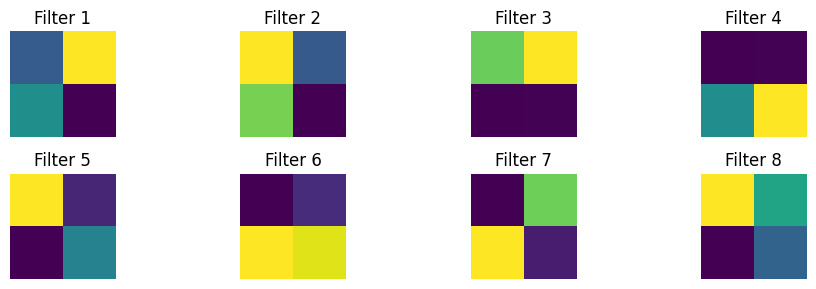

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras import layers, models

iris = load_iris()
X = StandardScaler().fit_transform(iris.data).reshape(-1, 2, 2, 1)
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

model = models.Sequential([
        layers.Input(shape=(2, 2, 1)),
            layers.Conv2D(8, (2, 2), activation="relu", padding="same"),
                layers.Flatten(),
                    layers.Dense(16, activation="relu"),
                        layers.Dense(3, activation="softmax")
                        ])

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",metrics=["accuracy"])

model.fit(X_train, y_train, epochs=50, verbose=0)
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print("Test Accuracy:", round(acc * 100, 2), "%")
print("Test Loss:", round(loss, 4))
filters = model.layers[0].get_weights()[0]
plt.figure(figsize=(10, 3))
for i in range(8):
  plt.subplot(2, 4, i + 1)
  plt.imshow(filters[:, :, 0, i], cmap="viridis")
  plt.title(f"Filter {i+1}")
  plt.axis("off")
plt.tight_layout()
plt.show()